# Shears — the fits, the map shear by shear, and the flow

Supports Supplementary Note 3 (and the comparison of Note 4), on the
disharmonic fold of `s03a`.

1. **Fits.** The paper's Euler velocity fitted to the sampled contacts and
   bedding twice, with the same training as the main text (amplitudes from zero
   by gradient descent with momentum, phases and biases by Adam): as in the
   paper, by **one one-way sweep** of its ray shears, and by **RK4**
   (`N_RK4` steps), whose map is the flow of its velocity.
2. **The RK4 fit's velocity and flow.** Its velocity field, and the
   trajectories along which its flow carries a grid of points.
3. **The velocity, ray by ray.** The sweep fit's velocity as a sum of one
   shear per ray, in the order the sweep applies them.
4. **The fitted map, shear by shear.** The sweep fit is the composition
   $\mathcal S_R\circ\cdots\circ\mathcal S_1$ of exact translations. Reference layer
   boundaries are carried through it, and their positions after every shear
   kept, so the figure can show the fold being built.
5. **Composing the shears.** The sweep fit's ray shears composed as exact
   translations, repeated `N` times at `1/N` each, three ways: one-way sweeps
   (`lie`, first order; `N = 1` is the fitted map), a sweep and its reverse
   (`strang`, second order) and Yoshida's triple jump of those (`yoshida`,
   fourth order), against RK4 at the same `N`. The distance to a fine RK4
   integration of the same velocity, its flow, is measured over `N_POINTS`
   points, and the restoration orbits of a grid of points are kept. In
   float64, so that the volume check sees the scheme and not the rounding.

Writes `results/shears.npz`, read by `s03d_shears_figures`. Runs in `curlew_dev`.

## Setup

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import numpy as np
import torch

sys.path.insert(0, str(Path("..").resolve()))      # publication/: diagnostics
import diagnostics

import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.flow import FlowOffset

curlew.device = "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

RES_DIR = Path("./results")
RES_DIR.mkdir(parents=True, exist_ok=True)

d = np.load("data/disharmonic_fold.npz")
AX = d["ax"]
NG, H_GRID = len(AX), AX[1] - AX[0]
GRID = np.stack(np.meshgrid(AX, AX, indexing="ij"), -1).reshape(-1, 2)
horizons, gp, gv = list(d["horizons"]), d["gp"], d["gv"]
C = CSet(gp=gp, gv=gv, eq=horizons)

## 1. The fits

In [2]:
FOURIER_SEED = 404
BAND = (1000.0, 4000.0)            # wavelength band (m)
N_FEATURES, N_DIRECTIONS = 128, 32
N_RK4 = 10                        # RK4 steps of the RK4 fit
EPOCHS = 2500
LOG_EVERY = 10                    # loss recorded every LOG_EVERY iterations
LR_ADAM = 5e-2                   # Adam rate for the phases and biases
LR_SGD, AMP_MOMENTUM = 5e-2, 0.9  # gradient descent with momentum for the amplitudes
WEIGHTS = dict(grad_loss="1.", eq_loss="1.")   # bedding and equal-elevation loss weights


def make_velocity():
    return euler_velocity(2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, seed=FOURIER_SEED,
                          length_scale_range=BAND, stream="alpha", activation="cubic",
                          energy_normalised=True)


def contact_values(field):
    # The fitted restored elevation of each horizon: its mean at that horizon's contacts.
    return [float(np.mean(diagnostics.sample_regular_grid(AX, AX, field, h))) for h in horizons]


def fit(name, integrator, n_steps):
    torch.manual_seed(405)
    velocity = make_velocity()
    event = restore(
        f"s03_{name}", C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
        n_steps=n_steps, integrator=integrator, depth_axis=1, init_std=0.0, sigma_floor=0.0,
        signed_normals=True, learning_rate=LR_ADAM, pin=torch.zeros(2),
        optimizer={"amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM)),
                   "shape": (torch.optim.Adam, dict(lr=LR_ADAM))},
    )
    for k, h in enumerate(horizons):
        event.addIsosurface(f"H{k}", seed=h)
    model = curlew.GeoModel([event])
    history = dict(iteration=[], loss=[])

    def record(epoch, epochs):                     # the loss every LOG_EVERY iterations
        if epoch % LOG_EVERY == 0:
            with torch.no_grad():
                history["iteration"].append(epoch)
                history["loss"].append(float(event.loss().total()))

    t0 = perf_counter()
    model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True, schedule=record)
    seconds = perf_counter() - t0
    with torch.no_grad():
        loss = float(event.loss().total())
        psi = np.asarray(model.predict(torch.tensor(GRID, dtype=torch.float32)).scalar, dtype=float).reshape(NG, NG)
        # ||D phi_h - I|| of one step (RK4), or of the whole map for the one-way sweep
        step = event.field.integrator.stability(torch.tensor(GRID[::7], dtype=torch.float32))
    history["iteration"].append(EPOCHS)
    history["loss"].append(loss)
    out = dict(event=event, velocity=velocity, psi=psi, loss=loss, seconds=seconds, step=step,
               history={key: np.array(v) for key, v in history.items()},
               levels=np.array(contact_values(psi)))
    print(f"{name}: {seconds:.0f} s, loss {loss:.2g}, "
          f"max ||D phi_h - I|| {step:.2f}")
    return out


fits = {"sweep": fit("sweep", "shear", 0), "rk4": fit("rk4", "rk4", N_RK4)}
sweep_integrator = fits["sweep"]["event"].field.integrator

L=0.001 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


sweep: 19 s, loss 0.00033, max ||D phi_h - I|| 10.21


L=0.015 grad_loss=0.004 eq_loss=0.011: : 2500/2500|


rk4: 92 s, loss 0.013, max ||D phi_h - I|| 0.56


### Quick look

The two fits against the data, before anything else runs: units of each fit,
its contacts (white), the data and the drawn horizons (dashed). To try a
change, run the setup, the fits and this cell only.

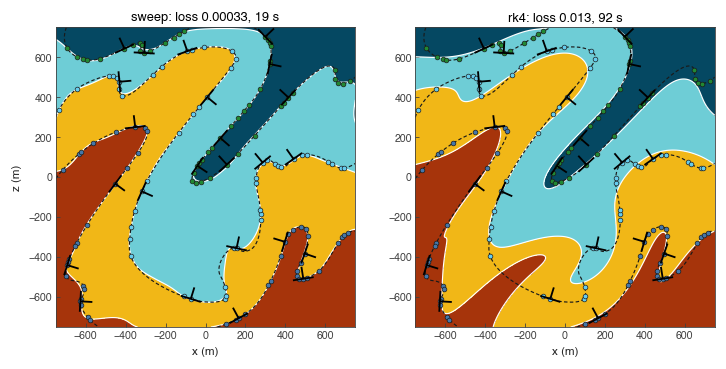

In [3]:
import matplotlib.pyplot as plt
import figstyle
figstyle.apply()

fig, axes = plt.subplots(1, 2, figsize=(figstyle.PRINT_WIDTH, 0.5 * figstyle.PRINT_WIDTH))
for ax, (name, f) in zip(axes, fits.items()):
    cmap, norm = figstyle.litho_cmap(np.arange(len(f["levels"]) + 1))
    ax.pcolormesh(AX, AX, np.digitize(f["psi"], np.sort(f["levels"])).T, cmap=cmap, norm=norm,
                  shading="auto", rasterized=True)
    ax.contour(AX, AX, f["psi"].T, levels=sorted(f["levels"]), colors="white", linewidths=0.7, linestyles="solid")
    for k in range(int(d["n_lines"])):
        ax.plot(*d[f"line_{k}"].T, color="0.1", lw=0.7, ls=(0, (3, 2)))
    for h, c in zip(horizons, figstyle.HORIZON_PALETTE):
        ax.scatter(*h.T, s=8, color=c, edgecolors="0.1", linewidths=0.4, zorder=5)
    figstyle.draw_younging(ax, gp, gv, color="k", quiver_scale=0.008)
    ax.set_title(f"{name}: loss {f['loss']:.2g}, {f['seconds']:.0f} s")
    ax.set_xlim(AX[0], AX[-1])
    ax.set_ylim(AX[0], AX[-1])
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
axes[0].set_ylabel("z (m)")
plt.show()

## 2. The RK4 fit: its velocity and its flow

The RK4 fit's map is the flow of its velocity, so its velocity field and the
trajectories along which it carries points describe the whole map. The
trajectories are traced from a grid of present-day points back to the
reference, with `N_TRACE` RK4 steps.

In [4]:
N_TRACE = 200
trace_starts = torch.tensor([[x, z] for x in np.linspace(-600, 600, 7) for z in np.linspace(-600, 600, 7)],
                            dtype=torch.float32)
rk4_vel = fits["rk4"]["velocity"]
with torch.no_grad():
    ax_v = np.linspace(AX[0], AX[-1], 151)
    grid_v = torch.tensor(np.stack(np.meshgrid(ax_v, ax_v, indexing="ij"), -1).reshape(-1, 2), dtype=torch.float32)
    rk4_v_grid = rk4_vel(grid_v)
    stepper, x, path = FlowOffset(rk4_vel, n_steps=1, integrator="rk4"), trace_starts, [trace_starts]
    for _ in range(N_TRACE):
        x = stepper._integrate(x, sign=-1.0, duration=1.0 / N_TRACE, n_steps=1, velocity=rk4_vel)
        path.append(x)
rk4_paths = torch.stack(path).numpy()                                          # (steps + 1, points, 2)
print(f"RK4 fit: largest speed {float(rk4_v_grid.norm(dim=1).max()):.0f} m per unit time, "
      f"largest displacement {np.linalg.norm(rk4_paths[-1] - rk4_paths[0], axis=1).max():.0f} m")

RK4 fit: largest speed 1336 m per unit time, largest displacement 1190 m


## 3. The RK4 fit's velocity, ray by ray

The velocity of the RK4 fit is the one whose flow is a fitted map, so it is the one worth
decomposing (the velocity of the sweep fit is only the sum of its shears; the sweep does not
follow its flow). It is written as one shear per ray, from the shear integrator's plan, so the
rays come in sweep order. Each ray's field is
$\sum\boldsymbol C\cos(\boldsymbol\Omega\cdot\boldsymbol x+o)$ over its modes and harmonics.
Nothing is integrated here.

In [5]:
NG_RAYS = 151                     # grid of the ray fields kept for the figure
N_SHOWN = 4                       # strongest rays kept
ax_r = np.linspace(AX[0], AX[-1], NG_RAYS)
grid_r = torch.tensor(np.stack(np.meshgrid(ax_r, ax_r, indexing="ij"), -1).reshape(-1, 2), dtype=torch.float32)
with torch.no_grad():
    velocity = fits["rk4"]["velocity"]
    plan = sweep_integrator._shear_plan(velocity, grid_r, None)     # sweep order (same bank)
    rays = torch.stack([torch.cos(torch.addr(off_g, grid_r @ dhat, a)) @ Cg for Cg, a, off_g, dhat, _ in plan])
    v_grid = velocity(grid_r)
    n_terms = velocity.shear_decomposition()[1].shape[0]
recon = float((rays.sum(0) - v_grid).norm(dim=1).max() / v_grid.norm(dim=1).max())
ray_rms = rays.norm(dim=2).pow(2).mean(dim=1).sqrt().numpy()
strongest = np.sort(np.argsort(ray_rms)[::-1][:N_SHOWN])            # kept in sweep order
print(f"{n_terms} shear terms in {len(plan)} rays; max |sum of rays - v| / max |v| = {recon:.1e}")
print("RMS speed per ray, in sweep order:", ray_rms.round(0).astype(int).tolist())
print("strongest rays (sweep position, from 1):", (strongest + 1).tolist())

384 shear terms in 32 rays; max |sum of rays - v| / max |v| = 5.5e-07
RMS speed per ray, in sweep order: [93, 59, 163, 160, 49, 145, 45, 56, 68, 35, 128, 27, 62, 54, 48, 87, 44, 41, 73, 37, 61, 45, 37, 86, 6, 52, 40, 116, 65, 55, 41, 65]
strongest rays (sweep position, from 1): [3, 4, 6, 11]


## 4. The fitted map, shear by shear

The unit boundaries (the fitted horizons, and one far below and one far above
the section), resolved every `DX` m along their length, are carried forward through the sweep fit's shears
one at a time. The pinned frame offset is added first, as `forward_map` does.

In [6]:
FAR, DX, REACH = 3000.0, 4.0, 3500.0          # far boundaries (m), resolution, half-length (m)
sweep = fits["sweep"]
integrator = sweep_integrator
# the fitted horizons, plus one boundary far below and one far above, so that every unit
# fills the section whatever the pinned frame offset and the displacements
z_bounds = np.r_[-FAR, np.sort(sweep["levels"]), FAR]
xs = np.arange(-REACH, REACH + DX, DX)
lines = np.stack([np.c_[xs, np.full_like(xs, z)] for z in z_bounds])            # (B, n, 2) reference
start = torch.tensor(lines.reshape(-1, 2), dtype=torch.float32) + integrator.frame_offset
with torch.no_grad():
    record = []
    integrator._integrate(start, sign=+1.0, n_steps=0, velocity=sweep["velocity"], record=record)
states = np.stack([start.numpy()] + [r.numpy() for r in record]).reshape(len(record) + 1, *lines.shape)
present = integrator.forward_map(torch.tensor(lines.reshape(-1, 2), dtype=torch.float32)).detach().numpy()

# How much each shear moves the rock in view: the RMS displacement of a grid of points, over those
# inside the section just before that shear acts. The grid reaches past the section so it stays covered.
G_STEP, G_REACH = 15.0, 1500.0
g_ax = np.arange(-G_REACH, G_REACH + G_STEP, G_STEP)
grid_pts = torch.tensor(np.stack(np.meshgrid(g_ax, g_ax, indexing="ij"), -1).reshape(-1, 2),
                        dtype=torch.float32) + integrator.frame_offset
with torch.no_grad():
    grid_rec = []
    integrator._integrate(grid_pts, sign=+1.0, n_steps=0, velocity=sweep["velocity"], record=grid_rec)
grid_states = np.stack([grid_pts.numpy()] + [r_.numpy() for r_ in grid_rec])
shear_rms = []
for k in range(1, len(grid_states)):
    in_view = (np.abs(grid_states[k - 1]) <= AX[-1]).all(axis=1)
    step = grid_states[k][in_view] - grid_states[k - 1][in_view]
    shear_rms.append(np.sqrt(np.mean(np.sum(step ** 2, axis=1))))
shear_rms = np.array(shear_rms)
print("RMS displacement of each shear in the section (m):", shear_rms.round(1).tolist())
print(f"{len(record)} shears; last state matches forward_map to "
      f"{np.abs(states[-1].reshape(-1, 2) - present).max():.1e} m")

RMS displacement of each shear in the section (m): [15.800000190734863, 21.5, 103.5999984741211, 36.599998474121094, 74.9000015258789, 40.099998474121094, 27.899999618530273, 93.0, 43.099998474121094, 36.70000076293945, 81.5, 19.600000381469727, 57.900001525878906, 17.299999237060547, 22.399999618530273, 88.5999984741211, 29.899999618530273, 39.79999923706055, 64.0, 34.099998474121094, 46.20000076293945, 22.200000762939453, 31.299999237060547, 84.0, 18.600000381469727, 42.20000076293945, 33.79999923706055, 28.5, 62.79999923706055, 17.700000762939453, 44.79999923706055, 46.70000076293945]
32 shears; last state matches forward_map to 0.0e+00 m


## 5. Composing the shears

The RK4 fit's velocity (decomposed in section 3) in float64: its shears, composed by
Lie-Trotter and Strang, against its flow. Errors are the greatest distance, over
`N_POINTS` present-day points, to its restoration by RK4 with `N_REF` steps.

In [13]:
curlew.dtype = torch.float64
torch.set_grad_enabled(False)
vel64 = make_velocity()
# Copy the learned parameters only: the frozen wavevectors are rebuilt in float64, so the modes on
# a ray stay parallel to float64 precision (float32 copies would show up in det J at ~1e-8).
learned = dict(vel64.named_parameters())
vel64.load_state_dict({k: v for k, v in fits["rk4"]["velocity"].state_dict().items() if k in learned},
                      strict=False)

N_POINTS, N_REF = 2000, 2048
N_VALUES = {s: (1, 2, 4, 8, 16, 32, 64, 128) for s in ("lie", "strang", "rk4")}
x0 = torch.tensor(np.random.default_rng(0).uniform(-700, 700, size=(N_POINTS, 2)))


def flow(scheme, n):
    if scheme == "rk4":
        return FlowOffset(vel64, n_steps=n, integrator="rk4")
    return FlowOffset(vel64, n_steps=n, integrator="shear", shear_scheme=scheme)


ref = flow("rk4", N_REF)._run(x0, sign=-1.0)
errors = {s: np.array([float((flow(s, n)._run(x0, sign=-1.0) - ref).norm(dim=1).max()) for n in ns])
          for s, ns in N_VALUES.items()}
displacement = float((ref - x0).norm(dim=1).max())
print(f"largest displacement of the flow {displacement:.0f} m")
for s, e in errors.items():
    print(f"{s:>8}: " + ", ".join(f"N={n}: {v:.3g}" for n, v in zip(N_VALUES[s], e))
          + f"; ratio per doubling {np.round(e[:-1] / e[1:], 1).tolist()}")

# Volume: |det J - 1| of one one-way sweep of these shears, and of RK4 at N_RK4 steps (the RK4 fit's map).
_, J_sweep = flow("lie", 1)._run(x0, sign=-1.0, jac=True)
_, J_rk4 = flow("rk4", N_RK4)._run(x0, sign=-1.0, jac=True)
det_err = {"sweep": float((torch.linalg.det(J_sweep) - 1).abs().max()),
           "rk4": float((torch.linalg.det(J_rk4) - 1).abs().max())}
print(f"max |det J - 1|: one-way sweep {det_err['sweep']:.1e}, RK4 N={N_RK4} {det_err['rk4']:.1e}")

largest displacement of the flow 1204 m
     lie: N=1: 861, N=2: 419, N=4: 216, N=8: 106, N=16: 54.1, N=32: 27.2, N=64: 13.6, N=128: 6.81; ratio per doubling [2.1, 1.9, 2.0, 2.0, 2.0, 2.0, 2.0]
  strang: N=1: 510, N=2: 186, N=4: 46.7, N=8: 9.87, N=16: 2.4, N=32: 0.595, N=64: 0.149, N=128: 0.0371; ratio per doubling [2.7, 4.0, 4.7, 4.1, 4.0, 4.0, 4.0]
     rk4: N=1: 541, N=2: 82.6, N=4: 6.99, N=8: 0.342, N=16: 0.0196, N=32: 0.00118, N=64: 7.24e-05, N=128: 4.49e-06; ratio per doubling [6.5, 11.8, 20.4, 17.5, 16.6, 16.3, 16.1]
max |det J - 1|: one-way sweep 1.9e-14, RK4 N=10 5.1e-04


**Restoration orbits.** For points on the drawn horizons, every intermediate position (one leg
per translation) of each composition, and a finely resolved RK4 path as the flow.

In [14]:
ORBITS = (("lie", 1), ("lie", 16), ("lie", 64), ("strang", 1), ("strang", 16))   # (scheme, N) drawn as orbits
# Start on the horizons: N_PER_HORIZON points evenly spaced along each drawn horizon, inside the section,
# so the orbits show where the horizons' points go as the fold is restored.
N_PER_HORIZON, EDGE = 10, 50.0                    # points per horizon; keep this far from the edges (m)


def along(line, n):
    line = line[np.isfinite(line).all(axis=1)]
    line = line[(np.abs(line) <= AX[-1] - EDGE).all(axis=1)]
    s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(line, axis=0), axis=1))]
    return line[np.searchsorted(s, np.linspace(0.0, s[-1], n + 2)[1:-1])]


starts = torch.tensor(np.vstack([along(d[f"line_{k}"], N_PER_HORIZON) for k in range(int(d["n_lines"]))]),
                      dtype=torch.float64)


def orbit(scheme, n):
    rec = []
    flow(scheme, n)._integrate(starts, sign=-1.0, n_steps=n, velocity=vel64, record=rec)
    return torch.stack([starts] + rec).numpy()                  # (legs + 1, points, 2)


def flow_path(k=400):
    f, x, path = flow("rk4", 1), starts, [starts]
    for _ in range(k):
        x = f._integrate(x, sign=-1.0, duration=1.0 / k, n_steps=1, velocity=vel64)
        path.append(x)
    return torch.stack(path).numpy()


orbits = {f"{s}_{n}": orbit(s, n) for s, n in ORBITS}
exact_path = flow_path()
for k, o in orbits.items():
    print(f"{k}: {o.shape[0] - 1} translations")
torch.set_grad_enabled(True)

lie_1: 32 translations
lie_16: 512 translations
lie_64: 2048 translations
strang_1: 63 translations
strang_16: 993 translations


torch.autograd.grad_mode.set_grad_enabled(mode=True)

## Save

In [15]:
arrays = dict(
    ax=AX, band=np.array(BAND), n_rk4=N_RK4,
    z_bounds=z_bounds, layer_states=states.astype(np.float32), shear_rms=shear_rms, frame_offset=integrator.frame_offset.numpy(),
    displacement=displacement, det_sweep=det_err["sweep"], det_rk4=det_err["rk4"],
    ax_v=ax_v, rk4_v_grid=rk4_v_grid.numpy().astype(np.float32), rk4_paths=rk4_paths,
    ax_rays=ax_r, v_grid=v_grid.numpy().astype(np.float32), rays=rays[strongest.copy()].numpy().astype(np.float32),
    ray_index=strongest + 1, ray_rms=ray_rms, recon=recon, n_terms=n_terms,
    starts=starts.numpy(), exact_path=exact_path, orbit_keys=np.array(list(orbits)),
    **{f"orbit_{k}": o for k, o in orbits.items()},
    **{f"nvals_{s}": np.array(ns) for s, ns in N_VALUES.items()},
    **{f"error_{s}": e for s, e in errors.items()},
)
for name, f in fits.items():
    arrays.update({f"{name}_psi": f["psi"].astype(np.float32), f"{name}_levels": f["levels"],
                   f"{name}_loss": f["loss"], f"{name}_loss_iteration": f["history"]["iteration"],
                   f"{name}_loss_curve": f["history"]["loss"], f"{name}_seconds": f["seconds"],
                   f"{name}_step": f["step"]})
np.savez(RES_DIR / "shears.npz", **arrays)
print("wrote", RES_DIR / "shears.npz")

wrote results/shears.npz
